# Sieci neuronowe i deep learning - Lab 6

## Modele sekwencyjne i attention

PyTorch.

W tym laboratorium pracujemy na plikach `winnie.txt` i `peterpan.txt`. Budujemy znakowy model jezykowy: z fragmentu tekstu model przewiduje kolejny znak. Na tym prostym zadaniu porownujemy RNN, LSTM/GRU oraz prosty mechanizm attention.

## Zadanie 1

Przygotuj dane tekstowe:

- wczytaj `winnie.txt` i `peterpan.txt`,
- wybierz korpus do treningu albo polacz oba teksty,
- opcjonalnie podmien teksty na wlasny korpus, jesli zachowasz dalszy format `raw_text`,
- oczysc tekst w prosty, jawny sposob,
- zbuduj slownik znakow,
- przygotuj pary: sekwencja znakow -> nastepny znak.


In [1]:
from pathlib import Path
import re
import textwrap

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

SEQ_LENGTH = 80
STEP = 3
MAX_CHARS = 80000
MAX_EXAMPLES = 14000
BATCH_SIZE = 128
EMBEDDING_DIM = 48
HIDDEN_DIM = 96
TRAIN_EPOCHS_SHORT = 3
TRAIN_EPOCHS_GENERATIVE = 5

# Propozycja wariantu GPU, jesli grupa chce lepsze probki tekstu:
# MAX_CHARS = 160000
# MAX_EXAMPLES = 30000
# TRAIN_EPOCHS_GENERATIVE = 8
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True


def find_data_dir():
    candidates = [Path("../dane"), Path("laboratoria/dane"), Path("dane"), Path("/content/dane")]
    for candidate in candidates:
        if (candidate / "winnie.txt").exists() and (candidate / "peterpan.txt").exists():
            return candidate

    fallback = Path("dane")
    fallback.mkdir(parents=True, exist_ok=True)
    return fallback


def ensure_text_files(data_dir):
    sources = {
        "peterpan.txt": "https://www.gutenberg.org/cache/epub/16/pg16.txt",
        "winnie.txt": "https://www.gutenberg.org/cache/epub/11/pg11.txt",
    }
    for filename, url in sources.items():
        path = data_dir / filename
        if path.exists():
            continue
        try:
            import urllib.request
            print(f"Pobieram fallback tekstowy: {filename}")
            urllib.request.urlretrieve(url, path)
        except Exception as exc:
            sample = (
                "This is a short fallback text for sequence modelling. "
                "It is used only when the notebook cannot download the public-domain corpus. "
            )
            path.write_text(sample * 2000, encoding="utf-8")
            print(f"Nie udalo sie pobrac {filename}; zapisano krotki fallback. Przyczyna: {exc}")


DATA_DIR = find_data_dir()
ensure_text_files(DATA_DIR)
print("Dane:", DATA_DIR.resolve())
print("Device:", DEVICE)


Dane: /home/balicz3k/Documents/master-studies/DeepLearning/lab6/dane
Device: cuda


In [2]:
# Zadanie 1a: wczytanie i czyszczenie tekstu.

# Wariant GPU zaproponowany w szablonie (komórka konfiguracyjna): więcej tekstu, więcej
# przykładów i 8 epok. Trening jednego modelu trwa na RTX 4060 kilka sekund, a przy
# domyślnych 5 epokach modele uczyły się głównie spacji i słowa "the".
if DEVICE.type == "cuda":
    MAX_CHARS = 160000
    MAX_EXAMPLES = 30000
    TRAIN_EPOCHS_GENERATIVE = 8


def read_text(name):
    # Pliki z Project Gutenberg (UTF-8, czasem z BOM na początku).
    return (DATA_DIR / name).read_text(encoding="utf-8-sig")


def strip_gutenberg(text):
    # Zostawiam tylko treść książki: między ostatnim znacznikiem "*** START OF"
    # a znacznikiem "*** END OF" (przed i po nich jest licencja Project Gutenberg).
    start = text.rfind("*** START OF")
    end = text.find("*** END OF")
    if start != -1:
        start = text.find("\n", start) + 1
    else:
        start = 0
    return text[start:end if end != -1 else len(text)]


def clean_text(text):
    text = strip_gutenberg(text).lower()
    # typograficzne cudzysłowy, apostrofy i myślniki -> zwykłe znaki ASCII (mniejszy słownik)
    text = text.replace("“", '"').replace("”", '"')
    text = text.replace("‘", "'").replace("’", "'")
    text = text.replace("—", "-").replace("–", "-")
    text = text.replace("_", "")             # podkreślenia oznaczają kursywę w plikach Gutenberga
    text = re.sub(r"\s+", " ", text)         # każdy ciąg białych znaków (także \r\n) -> jedna spacja
    return text.strip()


texts = {
    "winnie": clean_text(read_text("winnie.txt")),
    "peterpan": clean_text(read_text("peterpan.txt")),
}
for name, text in texts.items():
    print(f"{name}: {len(text):,} znaków po czyszczeniu")

# Jeden korpus: "Winnie-the-Pooh". Jedna książka ma jednolity styl, więc walidacja
# (końcówka tekstu) pochodzi z tego samego rozkładu co trening. MAX_CHARS ogranicza
# długość tekstu (książka ma mniej znaków niż limit, więc biorę ją całą).
CORPUS_NAME = "winnie"
raw_text = texts[CORPUS_NAME][:MAX_CHARS]

print(f"Korpus: {CORPUS_NAME}, {len(raw_text):,} znaków")
print(raw_text[:500])

winnie: 123,609 znaków po czyszczeniu
peterpan: 253,737 znaków po czyszczeniu
Korpus: winnie, 123,609 znaków
winnie-the-pooh by a. a. milne juveniles when we were very young "the best book of verses for children ever written."--a. edward newton in the atlantic monthly. fourteen songs from when we were very young words by a. a. milne. music by h. fraser-simson. decorations by e. h. shepard. the king's breakfast words by a. a. milne. music by h. fraser-simson. decorations by e. h. shepard essays not that it matters the sunny side if i may mystery story the red house mystery winnie-the-pooh by a. a. milne


**Skąd są teksty.** Oba pliki to wydania z Project Gutenberg. Adres z szablonu dla `winnie.txt` (`pg11`) wskazuje na „Alicję w Krainie Czarów”, a w dniu robienia laboratorium strona gutenberg.org była niedostępna (przerwa techniczna, zamiast tekstu zwracała stronę HTML). Dlatego pliki pobrałem z oficjalnego mirrora `gutenberg.pglaf.org`: „Winnie-the-Pooh” (eBook nr 67098) i „Peter Pan” (nr 16). Do treningu wybrałem „Winnie-the-Pooh”.

In [3]:
# Zadanie 1b: slownik znakow i kodowanie.

chars = sorted(set(raw_text))
char_to_id = {c: i for i, c in enumerate(chars)}
id_to_char = {i: c for c, i in char_to_id.items()}
vocab_size = len(chars)
encoded = np.array([char_to_id[c] for c in raw_text], dtype=np.int64)

print(f"Rozmiar słownika: {vocab_size} znaków")
print("Znaki:", repr("".join(chars)))
print("Początek po zakodowaniu:", encoded[:20])

Rozmiar słownika: 53 znaków
Znaki: ' !"&\'()*,-.0123456789:;?[]abcdefghijklmnopqrstuvwxyzæ'
Początek po zakodowaniu: [48 34 39 39 34 30  9 45 33 30  9 41 40 40 33  0 27 50  0 26]


In [4]:
# Zadanie 1c: pary sekwencja -> nastepny znak.


def make_examples(encoded_text, seq_length=SEQ_LENGTH, step=STEP, max_examples=MAX_EXAMPLES):
    # Okno o długości seq_length przesuwane co step znaków; celem jest znak tuż po oknie.
    starts = list(range(0, len(encoded_text) - seq_length, step))[:max_examples]
    X = np.stack([encoded_text[s:s + seq_length] for s in starts])
    y = np.array([encoded_text[s + seq_length] for s in starts], dtype=np.int64)
    return X, y


X, y = make_examples(encoded)

# Podział w kolejności tekstu: pierwsze 90% przykładów to trening, ostatnie 10% walidacja.
# Okna nachodzą na siebie (okno 80 znaków, przesunięcie 3), więc między zbiorami pomijam
# ceil(80 / 3) = 27 przykładów - inaczej końcowe okna treningu zawierałyby tekst walidacji.
n_train = int(0.9 * len(X))
gap = -(-SEQ_LENGTH // STEP)
X_train, y_train = X[:n_train], y[:n_train]
X_val, y_val = X[n_train + gap:], y[n_train + gap:]

train_dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_dataset = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(RANDOM_STATE))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Wszystkich przykładów: {len(X):,} (z pierwszych {len(X) * STEP + SEQ_LENGTH:,} znaków)")
print(f"train: {X_train.shape}, validation: {X_val.shape}, przerwa: {gap} przykładów")
print("Przykład:", repr("".join(id_to_char[i] for i in X_train[0])), "->", repr(id_to_char[int(y_train[0])]))

Wszystkich przykładów: 30,000 (z pierwszych 90,080 znaków)
train: (27000, 80), validation: (2973, 80), przerwa: 27 przykładów
Przykład: 'winnie-the-pooh by a. a. milne juveniles when we were very young "the best book ' -> 'o'


In [5]:
# Funkcje pomocnicze.
import copy
import math
import time


def plot_history(history, title):
    epochs = range(1, len(history["loss"]) + 1)
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
    axs[0].plot(epochs, history["loss"], marker="o", label="train")
    axs[0].plot(epochs, history["val_loss"], marker="o", label="validation")
    axs[0].set_title(f"{title}: loss")
    axs[1].plot(epochs, history["accuracy"], marker="o", label="train")
    axs[1].plot(epochs, history["val_accuracy"], marker="o", label="validation")
    axs[1].set_title(f"{title}: accuracy")
    for ax in axs:
        ax.set_xlabel("epoka")
        ax.set_xticks(list(epochs))
        ax.legend()
    plt.tight_layout()
    plt.show()


def perplexity(loss):
    # Cross-entropy liczona logarytmem naturalnym, więc perplexity = e^loss: model jest
    # średnio "tak niepewny", jakby wybierał równomiernie spośród tylu znaków.
    return math.exp(loss)


def print_score_table(rows):
    print(f"{'model':<16}{'parametry':>11}{'train_loss':>11}{'val_loss':>10}"
          f"{'val_ppl':>9}{'train_acc':>10}{'val_acc':>9}{'czas [s]':>10}")
    for r in rows:
        print(f"{r['name']:<16}{r['params']:>11,}{r['train_loss']:>11.4f}{r['val_loss']:>10.4f}"
              f"{r['val_perplexity']:>9.2f}{r['train_accuracy']:>10.4f}{r['val_accuracy']:>9.4f}{r['time_s']:>10.1f}")


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def run_epoch(model, loader, loss_fn, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)   # dropout włączony tylko w treningu
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            n = y_batch.size(0)
            total_loss += loss.item() * n
            correct += (logits.argmax(dim=1) == y_batch).sum().item()
            total += n
    return total_loss / total, correct / total


def train_torch_model(model, name, epochs=3, learning_rate=0.001):
    torch.manual_seed(RANDOM_STATE)
    model = model.to(DEVICE)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    best_val, best_state = float("inf"), None
    start = time.perf_counter()
    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(model, train_loader, loss_fn, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, loss_fn)
        for key, value in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[key].append(value)
        if va_loss < best_val:   # zapamiętuję wagi z najlepszej epoki wg validation loss
            best_val, best_state = va_loss, copy.deepcopy(model.state_dict())
        print(f"{name} epoka {epoch + 1}: loss {tr_loss:.4f}, val_loss {va_loss:.4f}, "
              f"acc {tr_acc:.4f}, val_acc {va_acc:.4f}")
    elapsed = time.perf_counter() - start
    model.load_state_dict(best_state)
    best = int(np.argmin(history["val_loss"]))
    row = {"name": name, "params": count_parameters(model), "best_epoch": best + 1,
           "train_loss": history["loss"][best], "val_loss": history["val_loss"][best],
           "val_perplexity": perplexity(history["val_loss"][best]),
           "train_accuracy": history["accuracy"][best], "val_accuracy": history["val_accuracy"][best],
           "time_s": elapsed}
    return model, history, row


# Wszystkie modele w tabeli uczą się tyle samo epok, żeby porównanie było uczciwe.
# Biorę dłuższy wariant z szablonu, bo modele GRU i GRU+attention służą też do generowania tekstu.
EPOCHS = TRAIN_EPOCHS_GENERATIVE

# Punkt odniesienia: model, który zawsze podaje rozkład częstości znaków z treningu.
freq = np.bincount(y_train, minlength=vocab_size) / len(y_train)
unigram_loss = float(-np.mean(np.log(freq[y_val] + 1e-12)))
print(f"Model częstości znaków: val_loss {unigram_loss:.4f}, perplexity {perplexity(unigram_loss):.2f}, "
      f"accuracy (zawsze '{id_to_char[int(freq.argmax())]}') {np.mean(y_val == freq.argmax()):.4f}")

Model częstości znaków: val_loss 2.9854, perplexity 19.79, accuracy (zawsze ' ') 0.1934


## Zadanie 2

Wytrenuj bazowy model rekurencyjny.

Porownaj, jak zachowuje sie prosty RNN na zadaniu predykcji nastepnego znaku. Zapisz loss, validation loss, accuracy i perplexity.

RNN epoka 1: loss 2.6796, val_loss 2.2984, acc 0.2758, val_acc 0.3438


RNN epoka 2: loss 2.2304, val_loss 2.1039, acc 0.3639, val_acc 0.3999


RNN epoka 3: loss 2.0819, val_loss 2.0114, acc 0.4001, val_acc 0.4390


RNN epoka 4: loss 1.9960, val_loss 1.9397, acc 0.4227, val_acc 0.4571


RNN epoka 5: loss 1.9253, val_loss 1.8848, acc 0.4413, val_acc 0.4672


RNN epoka 6: loss 1.8748, val_loss 1.8427, acc 0.4552, val_acc 0.4854


RNN epoka 7: loss 1.8258, val_loss 1.8122, acc 0.4716, val_acc 0.4978


RNN epoka 8: loss 1.7924, val_loss 1.7803, acc 0.4801, val_acc 0.5092


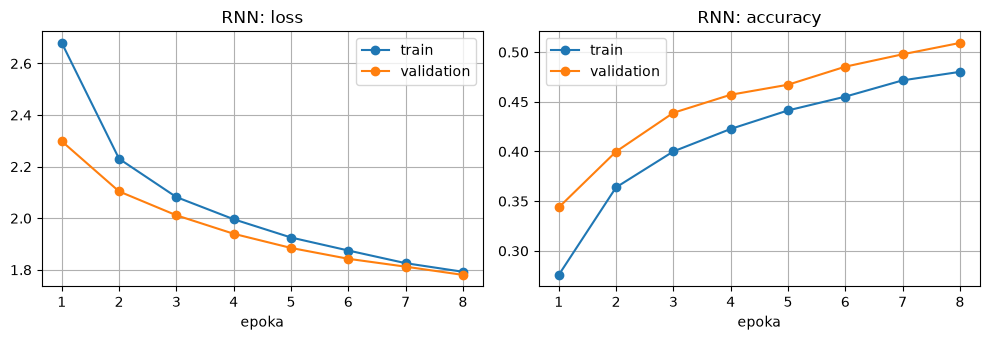

model             parametry train_loss  val_loss  val_ppl train_acc  val_acc  czas [s]
RNN                  21,701     1.7924    1.7803     5.93    0.4801   0.5092       2.9


In [6]:
# Zadanie 2: bazowy model rekurencyjny.


class RecurrentLM(nn.Module):
    def __init__(self, kind="rnn", vocab_size=vocab_size, embedding_dim=EMBEDDING_DIM, hidden_dim=HIDDEN_DIM):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)      # id znaku -> wektor 48 liczb
        layer = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.rnn = layer(embedding_dim, hidden_dim, batch_first=True)  # wejście (N, T, 48)
        self.dropout = nn.Dropout(0.2)                                  # typowa wartość, nie strojona
        self.out = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        outputs, _ = self.rnn(self.embedding(x))   # outputs: (N, T, hidden_dim)
        last = outputs[:, -1, :]                     # stan po ostatnim znaku sekwencji
        return self.out(self.dropout(last))          # logits (N, vocab_size)


torch_rows = []

rnn_model, rnn_history, rnn_row = train_torch_model(RecurrentLM("rnn"), "RNN", epochs=EPOCHS)
torch_rows.append(rnn_row)

plot_history(rnn_history, "RNN")
print_score_table(torch_rows)

**Zadanie 2 – RNN.** Punktem odniesienia jest model, który zawsze podaje częstości znaków z treningu: val_loss 2,985, perplexity 19,79, accuracy 0,193 (zawsze zgaduje spację).

Prosty RNN po 8 epokach ma val_loss 1,780, perplexity 5,93 i val_acc 0,509. Perplexity 5,9 znaczy, że model jest średnio tak niepewny, jakby wybierał spośród ok. 6 znaków, a nie spośród 20 jak model częstości. Loss treningowy (1,792) i walidacyjny są prawie równe, a oba wciąż spadały w ostatniej epoce, więc model nie jest przeuczony – raczej niedouczony.

## Zadanie 3

Porownaj LSTM i GRU.

Sprawdz, czy bramkowane modele rekurencyjne latwiej ucza sie zaleznosci w tekscie niz prosty RNN. Wygeneruj probki tekstu dla kilku temperatur i ustawien top-k. Nie oczekujemy jeszcze pieknej prozy: sprawdzamy, czy model uczy sie lokalnej skladni znakow, spacji i krotkich slow lepiej niz losowy generator.


LSTM epoka 1: loss 2.7986, val_loss 2.3921, acc 0.2469, val_acc 0.3269


LSTM epoka 2: loss 2.3086, val_loss 2.1696, acc 0.3406, val_acc 0.3828


LSTM epoka 3: loss 2.1375, val_loss 2.0518, acc 0.3859, val_acc 0.4090


LSTM epoka 4: loss 2.0303, val_loss 1.9599, acc 0.4123, val_acc 0.4413


LSTM epoka 5: loss 1.9432, val_loss 1.8966, acc 0.4356, val_acc 0.4564


LSTM epoka 6: loss 1.8730, val_loss 1.8325, acc 0.4557, val_acc 0.4834


... (6 outputs left out)

GRU epoka 5: loss 1.8309, val_loss 1.7881, acc 0.4658, val_acc 0.4891


GRU epoka 6: loss 1.7526, val_loss 1.7338, acc 0.4888, val_acc 0.5099


GRU epoka 7: loss 1.6958, val_loss 1.7062, acc 0.5059, val_acc 0.5035


GRU epoka 8: loss 1.6526, val_loss 1.6690, acc 0.5158, val_acc 0.5237


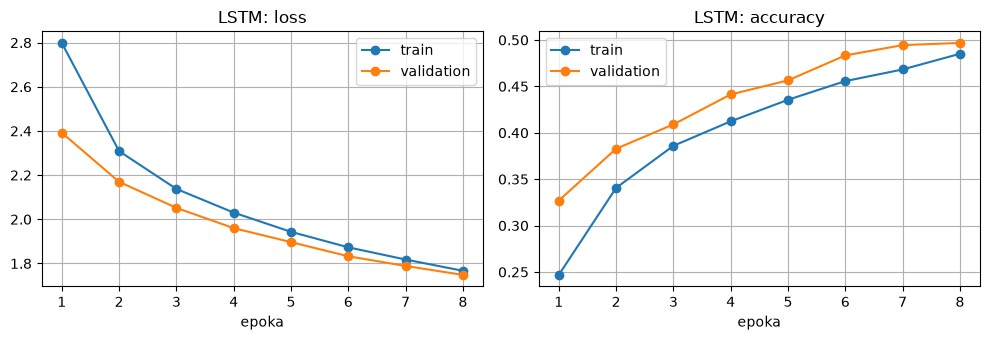

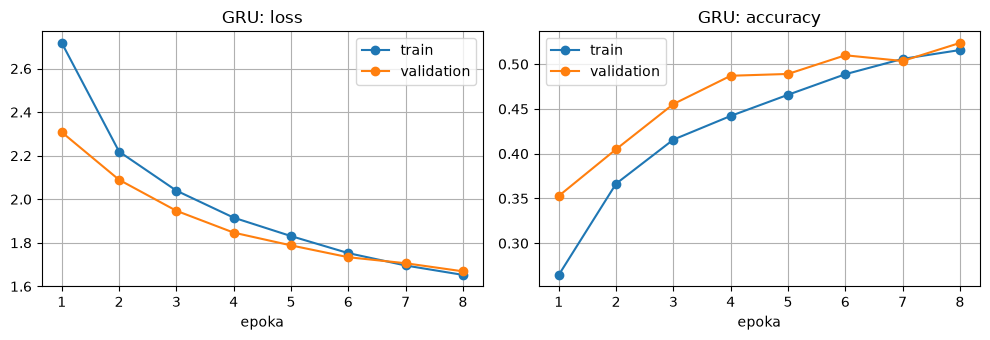

model             parametry train_loss  val_loss  val_ppl train_acc  val_acc  czas [s]
RNN                  21,701     1.7924    1.7803     5.93    0.4801   0.5092       2.9
LSTM                 63,749     1.7667    1.7482     5.74    0.4851   0.4968       2.9
GRU                  49,733     1.6526    1.6690     5.31    0.5158   0.5237       2.9


In [7]:
# Zadanie 3a: LSTM i GRU.

lstm_model, lstm_history, lstm_row = train_torch_model(RecurrentLM("lstm"), "LSTM", epochs=EPOCHS)
torch_rows.append(lstm_row)

gru_model, gru_history, gru_row = train_torch_model(RecurrentLM("gru"), "GRU", epochs=EPOCHS)
torch_rows.append(gru_row)

plot_history(lstm_history, "LSTM")
plot_history(gru_history, "GRU")
print_score_table(torch_rows)

**Zadanie 3a – LSTM i GRU.** Najlepszy jest GRU: val_loss 1,669 (perplexity 5,31) i val_acc 0,524. LSTM ma val_loss 1,748, czyli niższy niż RNN (1,780), ale niższe accuracy (0,497 wobec 0,509). Loss ocenia całe rozkłady prawdopodobieństwa, a accuracy tylko to, czy najwyżej oceniony znak jest prawidłowy, więc te miary nie muszą się zgadzać.

Bramki pomagają, ale przy 8 epokach różnice są niewielkie. LSTM ma najwięcej parametrów (63 749) i na początku uczy się najwolniej (po 1. epoce val_loss 2,392 wobec 2,298 dla RNN i 2,308 dla GRU). Przy oknie 80 znaków i krótkim treningu przewaga bramek w zapamiętywaniu długich zależności nie zdąży się w pełni pokazać.

In [8]:
# Zadanie 3b: generowanie tekstu.

sampling_generator = torch.Generator().manual_seed(RANDOM_STATE)


def sample_from_logits(logits, temperature=1.0, top_k=None):
    logits = logits.detach().float().cpu() / temperature   # T < 1 wyostrza rozkład, T > 1 spłaszcza
    if top_k is not None:
        kth = torch.topk(logits, top_k).values[-1]
        logits = logits.masked_fill(logits < kth, float("-inf"))   # zostaje k najbardziej prawdopodobnych
    probs = torch.softmax(logits, dim=-1)
    return int(torch.multinomial(probs, 1, generator=sampling_generator))


def encode_seed(seed):
    ids = [char_to_id[c] for c in seed.lower() if c in char_to_id]   # znaki spoza słownika pomijam
    ids = ids[-SEQ_LENGTH:]
    pad = [char_to_id[" "]] * (SEQ_LENGTH - len(ids))                # krótszy seed: spacje z lewej
    return pad + ids


def make_generation_seed(example_index=0, length=60):
    return "".join(id_to_char[int(i)] for i in X_val[example_index][-length:])


def generate_text(model, seed, num_chars=300, temperature=0.7, top_k=10):
    model.eval()
    context = encode_seed(seed)
    generated = []
    with torch.no_grad():
        for _ in range(num_chars):
            x = torch.tensor([context[-SEQ_LENGTH:]], device=DEVICE)
            next_id = sample_from_logits(model(x)[0], temperature, top_k)
            generated.append(id_to_char[next_id])
            context.append(next_id)   # wygenerowany znak staje się częścią wejścia
    return "".join(generated)


# Model do generowania: lepszy z LSTM i GRU według validation loss.
gen_name, gen_model = min([("LSTM", lstm_model, lstm_row), ("GRU", gru_model, gru_row)],
                          key=lambda t: t[2]["val_loss"])[:2]
seed = make_generation_seed(example_index=0)
settings = [(0.45, 5), (0.7, 10), (0.9, 20)]

print(f"Model: {gen_name}. Seed (koniec przykładu walidacyjnego): {seed!r}\n")
for temperature, top_k in settings:
    print(f"--- temperature={temperature}, top_k={top_k}")
    print(textwrap.fill(seed + "|" + generate_text(gen_model, seed, 300, temperature, top_k), 100))
    print()

Model: GRU. Seed (koniec przykładu walidacyjnego): ' say that, and as he opened his mouth to say something else,'

--- temperature=0.45, top_k=5
 say that, and as he opened his mouth to say something else,| and the said his said pooh, "i said
piglet someted to he we the to he the some the said pooh, "i had a to he said in and in the bear,
and then he said pooh. "in think it mise the think and somest the bear," said pooh. "i said peacked
the said the been think out it was been then as bear, "is and the

--- temperature=0.7, top_k=10
 say that, and as he opened his mouth to say something else,| he his house tree with reard ag at is.
and piglet belf the pooh. "of to the mise say site and pooh he mump some." "so doon as thing. "i
have side at a las that at mime im is he the pigked to thous on to so bear," he for and it ie said
pooh, "in i for he were a coull-on, and him that thing and said

--- temperature=0.9, top_k=20


 say that, and as he opened his mouth to say something else,| and the could could bery said a and of
he theand, would dit. been backing in chriftenton it wan as trat miping, we somen, no the bastimell
collut it was pooh have bustire in bike a beeni's that somenn, and him sapy care, whisely uspes he
pear say," said pook of you store, look pooh. "the been tell



**Zadanie 3b – generowanie.** Model GRU nauczył się lokalnej budowy tekstu: spacji między słowami, cudzysłowów i przecinków oraz częstych słów i imion („said pooh”, „piglet”, „the bear”). Nie nauczył się sensu zdań.
- **temperature 0,45, top_k 5:** tekst jest najbardziej poprawny, ale powtarzalny – ciągle te same słowa („said”, „the”, „pooh”).
- **temperature 0,7, top_k 10:** więcej różnych słów, część poprawna („house tree”, „piglet”), część zmyślona („mump”, „pigked”).
- **temperature 0,9, top_k 20:** najwięcej nieistniejących słów („chriftenton”, „bustire”), bo model częściej losuje mniej prawdopodobne znaki.

Niższa temperatura i mniejsze top_k dają bezpieczniejszy, ale nudniejszy tekst; wyższe – bardziej różnorodny, ale z większą liczbą błędów.

## Zadanie 4

Dodaj attention do modelu sekwencyjnego.

W poprzednich zadaniach model RNN/LSTM/GRU podejmowal decyzje na podstawie ostatniego stanu ukrytego. Teraz sprawdzamy inny wariant: GRU zwraca wszystkie stany ukryte, a proste attention pooling uczy sie, ktore pozycje sekwencji sa najwazniejsze dla predykcji nastepnego znaku.

Celem nie jest zalozenie, ze attention na pewno poprawi wynik. Celem jest uczciwe porownanie: trenujemy model z attention na tym samym zadaniu, dodajemy go do tabeli i sprawdzamy validation loss, perplexity oraz accuracy. Na koncu generujemy tez krotka probke tekstu z modelu `GRU+attention`, zeby porownanie nie konczylo sie sama tabela.


GRU+attention epoka 1: loss 3.1055, val_loss 2.9919, acc 0.1747, val_acc 0.1934


GRU+attention epoka 2: loss 3.0281, val_loss 2.9875, acc 0.1811, val_acc 0.1934


GRU+attention epoka 3: loss 3.0178, val_loss 2.9878, acc 0.1811, val_acc 0.1934


GRU+attention epoka 4: loss 3.0130, val_loss 2.9843, acc 0.1811, val_acc 0.1934


GRU+attention epoka 5: loss 3.0059, val_loss 2.9816, acc 0.1811, val_acc 0.1934


GRU+attention epoka 6: loss 2.9978, val_loss 2.9773, acc 0.1810, val_acc 0.1934


... (6 outputs left out)

GRU+att+ostatni epoka 5: loss 1.7920, val_loss 1.7697, acc 0.4784, val_acc 0.4887


GRU+att+ostatni epoka 6: loss 1.7164, val_loss 1.7169, acc 0.4994, val_acc 0.5008


GRU+att+ostatni epoka 7: loss 1.6609, val_loss 1.6830, acc 0.5115, val_acc 0.5126


GRU+att+ostatni epoka 8: loss 1.6107, val_loss 1.6614, acc 0.5250, val_acc 0.5214


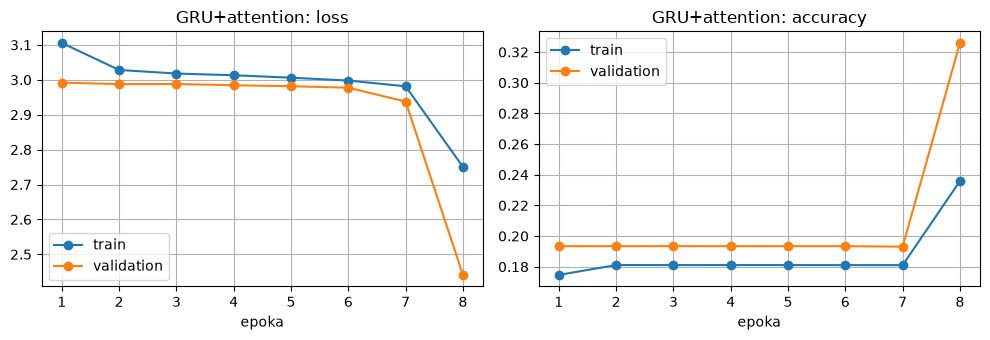

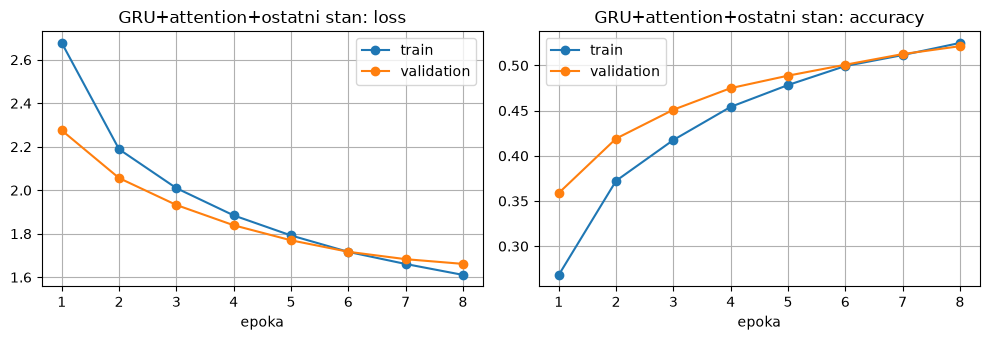

model             parametry train_loss  val_loss  val_ppl train_acc  val_acc  czas [s]
RNN                  21,701     1.7924    1.7803     5.93    0.4801   0.5092       2.9
LSTM                 63,749     1.7667    1.7482     5.74    0.4851   0.4968       2.9
GRU                  49,733     1.6526    1.6690     5.31    0.5158   0.5237       2.9
GRU+attention        49,830     2.7504    2.4410    11.49    0.2359   0.3259       3.2
GRU+att+ostatni      54,918     1.6107    1.6614     5.27    0.5250   0.5214       3.3


In [9]:
# Zadanie 4a: GRU z attention pooling.


class AttentionGRULM(nn.Module):
    def __init__(self, vocab_size=vocab_size, embedding_dim=EMBEDDING_DIM, hidden_dim=HIDDEN_DIM):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.gru = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.score = nn.Linear(hidden_dim, 1)   # jedna liczba "ważności" na pozycję
        self.dropout = nn.Dropout(0.2)
        self.out = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, return_attention=False):
        outputs, _ = self.gru(self.embedding(x))              # (N, T, H): stan po każdym znaku
        weights = torch.softmax(self.score(outputs).squeeze(-1), dim=1)   # (N, T), suma po T = 1
        context = (weights.unsqueeze(-1) * outputs).sum(dim=1)            # (N, H): ważona suma stanów
        logits = self.out(self.dropout(context))
        return (logits, weights) if return_attention else logits


attention_model, attention_history, attention_row = train_torch_model(
    AttentionGRULM(), "GRU+attention", epochs=EPOCHS)
torch_rows.append(attention_row)


# Wariant porównawczy: wektor kontekstu z attention połączony z ostatnim stanem GRU.
# Samo attention pooling zaczyna od równych wag 1/80, czyli od średniej ze wszystkich stanów,
# w której ginie informacja o ostatnich znakach - a to one najbardziej mówią o następnym znaku.
class AttentionLastGRULM(AttentionGRULM):
    def __init__(self, vocab_size=vocab_size, embedding_dim=EMBEDDING_DIM, hidden_dim=HIDDEN_DIM):
        super().__init__(vocab_size, embedding_dim, hidden_dim)
        self.out = nn.Linear(2 * hidden_dim, vocab_size)   # [kontekst, ostatni stan]

    def forward(self, x, return_attention=False):
        outputs, _ = self.gru(self.embedding(x))
        weights = torch.softmax(self.score(outputs).squeeze(-1), dim=1)
        context = (weights.unsqueeze(-1) * outputs).sum(dim=1)
        features = torch.cat([context, outputs[:, -1, :]], dim=1)
        logits = self.out(self.dropout(features))
        return (logits, weights) if return_attention else logits


attention_last_model, attention_last_history, attention_last_row = train_torch_model(
    AttentionLastGRULM(), "GRU+att+ostatni", epochs=EPOCHS)
torch_rows.append(attention_last_row)

plot_history(attention_history, "GRU+attention")
plot_history(attention_last_history, "GRU+attention+ostatni stan")
print_score_table(torch_rows)

**Zadanie 4a – attention.** Model GRU+attention zbudowany tak jak w poleceniu (sama ważona suma stanów) uczy się bardzo wolno. Przez pierwsze 6 epok val_loss stoi na poziomie modelu częstości znaków (2,98–2,99 wobec 2,985), a ruszył dopiero w 7. i 8. epoce. Po 8 epokach ma val_loss 2,441, perplexity 11,49 i val_acc 0,326, czyli wyraźnie gorzej niż sam GRU.

Moje wyjaśnienie: na początku wagi attention są równe (1/80), więc wektor kontekstu to średnia ze wszystkich 80 stanów. Informacja o ostatnich znakach, które najbardziej mówią o następnym, jest w tej średniej rozmyta, a gradient trafia do każdej pozycji tylko w 1/80. Model musi najpierw nauczyć się, gdzie patrzeć.

Dlatego dodałem wariant porównawczy: kontekst z attention połączony z ostatnim stanem GRU. Ma val_loss 1,661 (perplexity 5,27) i val_acc 0,521, czyli praktycznie tyle samo co GRU (1,669 i 0,524). Na tym zadaniu attention nie daje mierzalnej poprawy względem ostatniego stanu.

Kontekst: " perhaps he wouldn't say that, and as he opened his mouth to say something else,"
Prawdziwy następny znak: ' ', miejsce w rankingu modelu: 1, p = 0.805
Najbardziej prawdopodobne znaki: ' ': 0.805, '"': 0.074, ',': 0.017, 'e': 0.015, 'd': 0.013
Pozycje z największą wagą: 75 ('e'): 0.015, 76 ('l'): 0.026, 77 ('s'): 0.038, 78 ('e'): 0.065, 79 (','): 0.844
Waga ostatnich 10 pozycji razem: 0.998 (przy równych wagach byłoby 0.125)


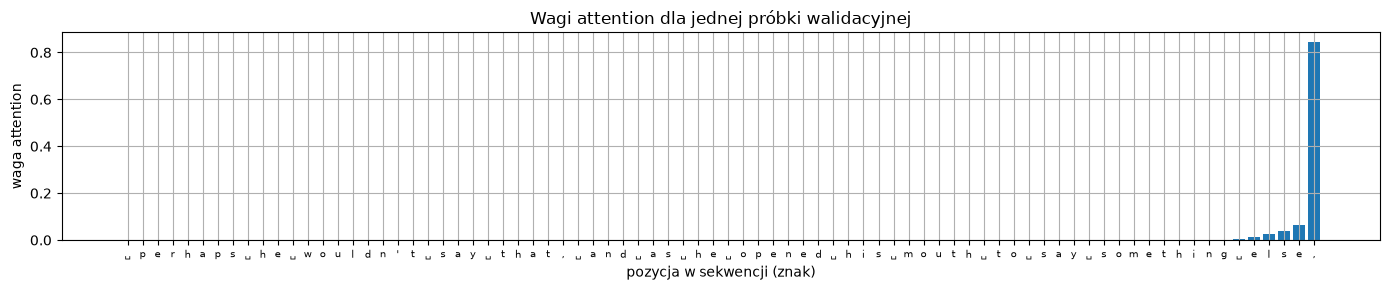

Średnio na walidacji: ostatnie 10 pozycji mają razem wagę 0.984, pierwsze 40 pozycji 0.001

===== GRU
--- temperature=0.45, top_k=5
 say that, and as he opened his mouth to say something else,| and the said his said pooh, "i said
piglet someted to he we the to he the some the said pooh, "i had a to he said in and in the bear,
and then he said pooh. "in think it mise the think and somest the bear," said pooh. "i said peacked
the said the been think out it was been then as bear, "is and the
--- temperature=0.7, top_k=10
 say that, and as he opened his mouth to say something else,| he his house tree with reard ag at is.
and piglet belf the pooh. "of to the mise say site and pooh he mump some." "so doon as thing. "i
have side at a las that at mime im is he the pigked to thous on to so bear," he for and it ie said
pooh, "in i for he were a coull-on, and him that thing and said

===== GRU+attention
--- temperature=0.45, top_k=5


 say that, and as he opened his mouth to say something else,| thhe id sit he the the sad thhe ete
the and ern een ann ho he ad antn thhee annt it het ad ente thee ee te ete ethe rron int hee thee it
hee the ann thoee ern thet e eer eote theet in e tha theet ha saeeie thhee thee a thhee tee e enet
ereree the eret enr reeee seete thee et it ann theee thee e ee
--- temperature=0.7, top_k=10
 say that, and as he opened his mouth to say something else,|e  adint ot o then theelr erter tat is.
ad ind on to ro thee te the it ot rtin he sal hi sig eoo rtthe hell noetle th hhaan thho shane s
ooeerer rtet anr setl se and the oe inn atde hadr saeen roes on toreoee teh  halt wad thi ane
serthed and innn wwe hoe erorr th eeron toee fie tthe thie rars ann w

===== GRU+attention+ostatni stan
--- temperature=0.45, top_k=5


 say that, and as he opened his mouth to say something else,| and then it what sore head, and said
pooh. "i said pooh. "what a dong the sorething his said pooh. "and pooh said is and said piglet said
piglet said round then thing and then he think the said the bear, and he said pooh had pooh he said
past the said pooh, "what the to call the said pooh. "what so
--- temperature=0.7, top_k=10
 say that, and as he opened his mouth to say something else,| he his hought. "nown't said pooh. "you
say piglet, "of the stered the to had when a said pooh. "nother, and pooh said pooh. "whes and
sometore-pooh. "yous that all one im as i some-pook said was been to somether and then pooh and said
pooh, then pobloughte--wa cought bearers it, thent it mars ontie


In [10]:
# Zadanie 4b: wizualizacja i interpretacja wag attention.

attention_model.eval()
sample_index = 0
x_sample = torch.from_numpy(X_val[sample_index:sample_index + 1]).to(DEVICE)
true_next = int(y_val[sample_index])
with torch.no_grad():
    logits, weights = attention_model(x_sample, return_attention=True)
sample_probabilities = torch.softmax(logits[0], dim=-1).cpu().numpy()
sample_weights = weights[0].cpu().numpy()

order = np.argsort(-sample_probabilities)
rank = int(np.where(order == true_next)[0][0]) + 1
context_text = "".join(id_to_char[int(i)] for i in X_val[sample_index])
print(f"Kontekst: {context_text!r}")
print(f"Prawdziwy następny znak: {id_to_char[true_next]!r}, miejsce w rankingu modelu: {rank}, "
      f"p = {sample_probabilities[true_next]:.3f}")
print("Najbardziej prawdopodobne znaki:",
      ", ".join(f"{id_to_char[int(i)]!r}: {sample_probabilities[i]:.3f}" for i in order[:5]))
top_pos = np.argsort(-sample_weights)[:5]
print("Pozycje z największą wagą:",
      ", ".join(f"{p} ({context_text[p]!r}): {sample_weights[p]:.3f}" for p in sorted(top_pos)))
print(f"Waga ostatnich 10 pozycji razem: {sample_weights[-10:].sum():.3f} "
      f"(przy równych wagach byłoby {10 / SEQ_LENGTH:.3f})")

fig, ax = plt.subplots(figsize=(14, 3))
ax.bar(range(SEQ_LENGTH), sample_weights)
ax.set_xticks(range(SEQ_LENGTH))
ax.set_xticklabels([c if c != " " else "␣" for c in context_text], fontsize=7)
ax.set_xlabel("pozycja w sekwencji (znak)")
ax.set_ylabel("waga attention")
ax.set_title("Wagi attention dla jednej próbki walidacyjnej")
plt.tight_layout()
plt.show()

# Średnie wagi po pozycjach dla całej walidacji - czy wzór z jednej próbki jest typowy?
with torch.no_grad():
    all_weights = torch.cat([attention_model(xb.to(DEVICE), return_attention=True)[1].cpu()
                             for xb, _ in val_loader]).numpy()
mean_weights = all_weights.mean(axis=0)
print(f"Średnio na walidacji: ostatnie 10 pozycji mają razem wagę {mean_weights[-10:].sum():.3f}, "
      f"pierwsze 40 pozycji {mean_weights[:40].sum():.3f}")

# Próbki tekstu z GRU+attention - te same seed i ustawienia co w zadaniu 3b
# (generator losowy od nowa, więc różnice wynikają z modelu, nie z losowania).
for name, model in [("GRU", gru_model), ("GRU+attention", attention_model),
                    ("GRU+attention+ostatni stan", attention_last_model)]:
    sampling_generator.manual_seed(RANDOM_STATE)
    print(f"\n===== {name}")
    for temperature, top_k in settings[:2]:
        print(f"--- temperature={temperature}, top_k={top_k}")
        print(textwrap.fill(seed + "|" + generate_text(model, seed, 300, temperature, top_k), 100))

**Zadanie 4b – interpretacja wag.** Po treningu model z attention patrzy prawie wyłącznie na koniec sekwencji. W pokazanej próbce ostatni znak (przecinek) ma wagę 0,844, a ostatnie 10 pozycji razem 0,998. Na całej walidacji średnio ostatnie 10 pozycji ma wagę 0,984, a pierwsze 40 tylko 0,001. Prawdziwy następny znak (spacja po przecinku) model stawia na 1. miejscu z prawdopodobieństwem 0,805.

To rozsądne dla modelu znakowego: o następnym znaku decydują głównie ostatnie litery bieżącego słowa. Attention nauczyło się więc w praktyce tego, co GRU dostaje od razu w ostatnim stanie, i dlatego wariant z ostatnim stanem nie zyskuje nic więcej.

Tekst z GRU+attention (po 8 epokach) to ciągi częstych liter („thhee”, „ann”) z nielicznymi słowami („the”, „and”, „it”), czyli wyraźnie gorzej niż z GRU. Tekst z wariantu z ostatnim stanem jest podobny do GRU: poprawne „said pooh”, „piglet”, cudzysłowy i kropki, ale bez sensu całych zdań.